# ミズナラ年輪幅と気温の関係：年輪幅から過去の気温を推定できるか

北海道東部（阿寒湖付近）のミズナラ（*Quercus crispula*）の年輪幅と、釧路の年平均気温との関係を調べ、
年輪幅から過去の気温を推定できるかを検討する。大学1年次のPython課題をもとに、再現しやすい形に整理し直したもの。

**流れ**
1. データの読み込みと整形（気温の欠測処理・標高補正）
2. 年輪幅の可視化（コア単位 → 木単位）
3. 年輪幅と気温の相関
4. 回帰による気温の推定（単回帰・重回帰）
5. 期間を分けた検証と考察

## 0. 準備

In [1]:
import io
import urllib.request
import zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import japanize_matplotlib  # noqa: F401  日本語フォント設定（import するだけで有効）

pd.set_option("display.max_columns", None)
plt.rcParams["figure.dpi"] = 80  # ノートブックのファイルサイズを抑える

# notebooks/ から実行しても、リポジトリのルートから実行しても動くようにする
DATA_DIR = Path("../data") if Path("../data").exists() else Path("data")

# 釧路の気温を山地の調査地に合わせるための補正値（℃）
# 調査木の平均標高は約530 m。気温減率 0.6℃/100 m とすると 530 m × 0.006 ≒ 3.2℃ → 一律 -3℃ とする
TEMP_OFFSET = -3.0

## 1. データの読み込み

| ファイル | 内容 | 出典 |
|---|---|---|
| `trw_l.csv` | 大径木の年輪幅 (mm)、コア別 | J-STAGE Data（寺澤ほか, 2025） |
| `trw_m.csv` | 中径木の年輪幅 (mm)、コア別 | 同上 |
| `info_tree.csv` | 木の属性（緯度経度・標高・DBH・推定樹齢） | 同上 |
| `info_core.csv` | コアの属性 | 同上 |
| `Kushiro_kion.csv` | 釧路の月平均気温・年平均気温 | 気象庁の公開データから手作業で作成（リポジトリの `data/` に同梱） |

年輪データ（上4ファイル）は **CC BY-NC-ND 4.0** で公開されており、再配布を避けるためリポジトリには含めていない。
次のセルが配布元から自動でダウンロードして `data/` に保存する（すでにあればスキップ）。出典の詳細は README を参照。

In [2]:
TRW_URL = "https://jstagedata.jst.go.jp/ndownloader/articles/28592693/versions/1"  # 配布元の一括ダウンロードURL（zip）
TRW_FILES = ["trw_l.csv", "trw_m.csv", "info_tree.csv", "info_core.csv"]


def download_tree_ring_data(data_dir, url=TRW_URL, files=TRW_FILES):
    """年輪データを配布元からダウンロードして data_dir に保存する（すでにあれば何もしない）"""
    data_dir.mkdir(parents=True, exist_ok=True)
    missing = [f for f in files if not (data_dir / f).exists()]
    if not missing:
        print(f"年輪データは {data_dir}/ に揃っています（ダウンロード不要）")
        return

    print("ダウンロード中:", url)
    request = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"})
    try:
        with urllib.request.urlopen(request, timeout=60) as response:
            payload = response.read()
        with zipfile.ZipFile(io.BytesIO(payload)) as zf:
            names = {Path(n).name: n for n in zf.namelist()}
            for f in missing:
                (data_dir / f).write_bytes(zf.read(names[f]))  # 中身は改変せずそのまま保存
    except Exception as e:
        raise RuntimeError(
            f"年輪データのダウンロードに失敗しました: {e}\n"
            f"配布ページ（README参照）から手動でダウンロードし、{missing} を {data_dir}/ に置いてください。"
        ) from e
    print("保存しました:", ", ".join(missing))


download_tree_ring_data(DATA_DIR)

年輪データは ../data/ に揃っています（ダウンロード不要）


In [3]:
def read_trw(path):
    # 年を index にして昇順に並べる（元データは新しい年が上）
    return pd.read_csv(path, encoding="utf-8-sig", index_col="Year").sort_index()

trw_l = read_trw(DATA_DIR / "trw_l.csv")   # 大径木
trw_m = read_trw(DATA_DIR / "trw_m.csv")   # 中径木
info_tree = pd.read_csv(DATA_DIR / "info_tree.csv", encoding="utf-8-sig")
info_core = pd.read_csv(DATA_DIR / "info_core.csv", encoding="utf-8-sig")

print("大径木:", trw_l.shape, f"({trw_l.index.min()}-{trw_l.index.max()})")
print("中径木:", trw_m.shape, f"({trw_m.index.min()}-{trw_m.index.max()})")
trw_l.tail()

大径木: (357, 25) (1663-2019)
中径木: (108, 12) (1912-2019)


,Qm2311,Qm2341,Qm2342,Qm2351,Qm2391,Qm2402,Qm2421,Qm2422,Qm2431,Qm2432,Qm2451,Qm2452,Qm2461,Qm2462,Qm2463,Qm2471,Qm2472,Qm2481,Qm2491,Qm2492,Qm2521,Qm2522,Qm2551,Qm5441,Qm5442
Year,,,,,,,,,,,,,,,,,,,,,,,,,
2015,1.11,1.45,0.97,1.04,1.19,0.59,2.08,0.36,1.83,0.73,0.90,0.93,0.97,1.01,0.91,0.64,1.26,0.81,1.06,2.10,0.87,0.89,0.67,0.78,1.52
2016,1.55,1.57,1.10,0.82,1.02,1.17,1.05,0.46,1.24,0.26,0.66,0.94,1.17,1.16,1.23,0.75,0.84,0.59,1.35,2.76,0.58,0.70,0.98,0.78,1.73
2017,1.37,0.98,0.82,0.49,0.92,0.86,0.39,0.40,1.02,0.32,0.81,0.93,0.85,0.86,0.88,0.48,0.85,0.63,0.95,1.80,0.38,0.51,0.65,0.82,1.28
2018,NaN,0.90,0.99,0.67,1.17,1.01,0.36,0.26,1.68,0.35,0.54,1.01,1.07,1.09,1.23,0.56,1.20,0.45,1.00,1.44,NaN,NaN,0.63,0.92,1.43
2019,NaN,1.75,1.16,1.06,1.29,1.59,0.72,0.38,2.04,0.54,NaN,NaN,1.56,1.58,1.44,0.44,1.47,0.73,1.25,1.68,NaN,NaN,NaN,0.94,1.77


In [4]:
info_tree.head()

,treeID,species,latitude,longitude,elevation,dbh,height,age_mean,age_lower,age_upper
0,Qm231,Quercus_crispula,43.487N,144.135E,480,95,25.0,198,181,218
1,Qm234,Quercus_crispula,43.499N,144.130E,570,118,22.0,401,368,437
2,Qm235,Quercus_crispula,43.500N,144.129E,570,157,21.0,436,393,481
3,Qm239,Quercus_crispula,43.494N,144.141E,510,153,25.0,413,383,442
4,Qm240,Quercus_crispula,43.494N,144.141E,510,115,19.0,433,398,467


In [5]:
info_core.head()

,coreID,species,size,Dcore,Hcore,date,type,first,last,Ncore,mean,median,stdev,ar1,series_intercorrelation,p_value,missing_ring,unmeasured_ring
0,Qm2311,Quercus_crispula,Large,94.7,1.30,2018-05-12,Short,1850,2017,168,2.21,1.88,1.03,0.715,0.493,<0.001,0,0
1,Qm2341,Quercus_crispula,Large,118.9,1.06,2019-10-11,Short,1675,2019,345,1.24,1.08,0.78,0.763,0.429,<0.001,1,1
2,Qm2342,Quercus_crispula,Large,118.9,1.10,2019-10-11,Short,1684,2019,336,1.24,1.06,0.65,0.712,0.591,<0.001,0,0
3,Qm2351,Quercus_crispula,Large,155.5,1.02,2019-10-11,Short,1692,2019,328,1.39,1.25,0.59,0.621,0.574,<0.001,0,0
4,Qm2391,Quercus_crispula,Large,153.6,1.16,2019-10-10,Short,1684,2019,336,1.28,1.10,0.80,0.819,0.530,<0.001,0,0


## 2. 気温データの整形

`Kushiro_kion.csv` の先頭行はタイトル、2行目が列名。
気象庁の表に由来する記号（`×`：欠測、`]`：資料不足 など）が混じっているため、数値に変換できないものは欠測（NaN）として扱う。
その後、調査地の標高に合わせて `TEMP_OFFSET`（-3℃）を足す。

In [6]:
kion_raw = pd.read_csv(DATA_DIR / "Kushiro_kion.csv", header=1, encoding="utf-8-sig")
kion_raw["年"] = pd.to_numeric(kion_raw["年"], errors="coerce")
kion_raw["年の値"] = pd.to_numeric(kion_raw["年の値"], errors="coerce")  # 記号つきの値は NaN になる

# 年平均気温（補正後）: index=年
temp = (kion_raw.set_index("年")["年の値"] + TEMP_OFFSET).rename("temp")

print("欠測の年:", temp[temp.isna()].index.tolist())
print(f"有効な年: {temp.dropna().index.min()}-{temp.dropna().index.max()}（{temp.notna().sum()}年）")

欠測の年: [1889, 2025]
有効な年: 1890-2024（135年）


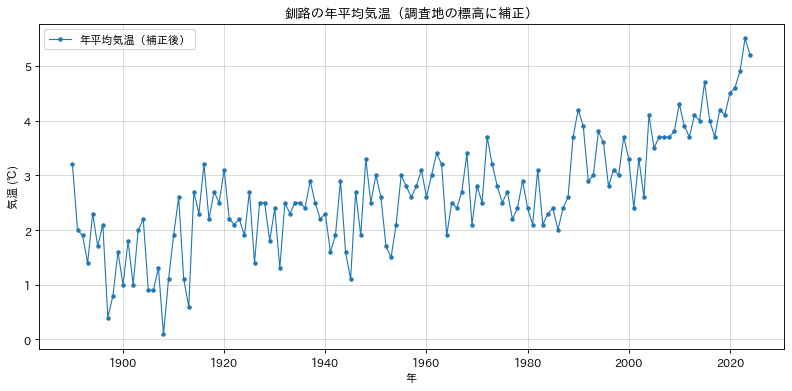

In [7]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(temp.index, temp.values, marker="o", markersize=3, linewidth=1, label="年平均気温（補正後）")
ax.set(title="釧路の年平均気温（調査地の標高に補正）", xlabel="年", ylabel="気温 (℃)")
ax.grid(alpha=0.5)
ax.legend()
fig.tight_layout()
plt.show()

## 3. 年輪幅の可視化

### 3-1. コア単位
まず全コアの系列をそのまま重ねて描く。

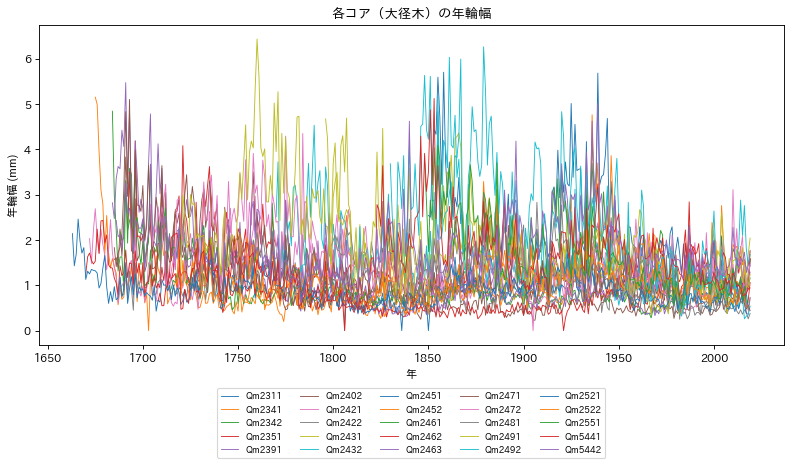

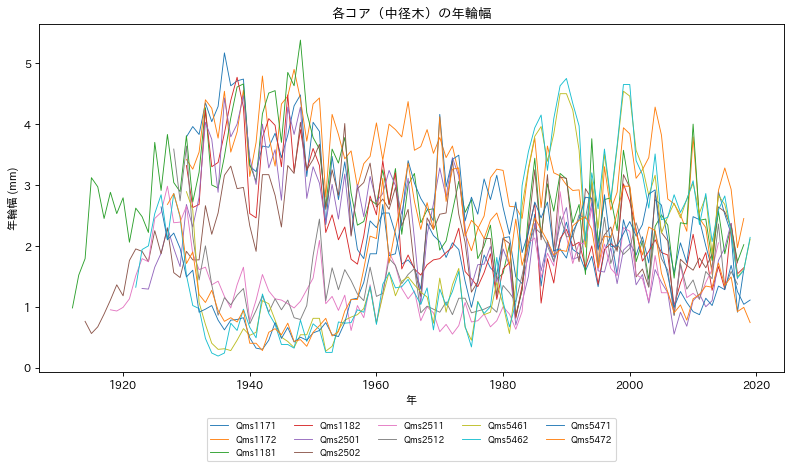

In [8]:
def plot_series(df, title, ylabel="年輪幅 (mm)", ncol=5, figsize=(10, 6)):
    """列ごとに1本の線を描き、凡例をグラフの下に置く"""
    fig, ax = plt.subplots(figsize=figsize)
    for col in df.columns:
        ax.plot(df.index, df[col], linewidth=0.8, label=col)
    ax.set(title=title, xlabel="年", ylabel=ylabel)
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=ncol, fontsize=8)
    fig.tight_layout()
    plt.show()

plot_series(trw_l, "各コア（大径木）の年輪幅")
plot_series(trw_m, "各コア（中径木）の年輪幅")

異なる木から選んだ3コア（中径木）だけを重ねて、木ごとの違いを見る。

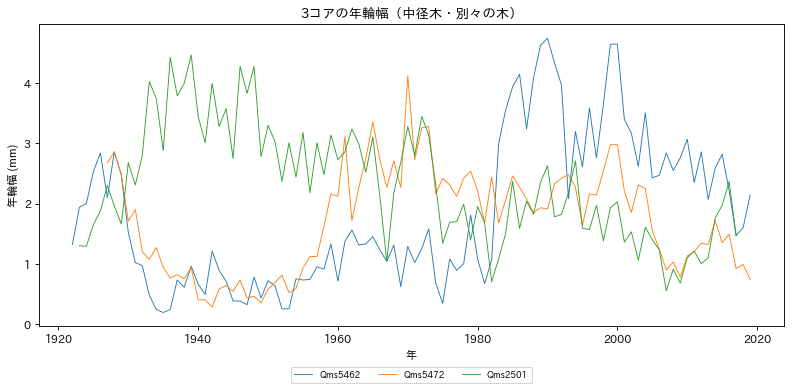

In [9]:
plot_series(trw_m[["Qms5462", "Qms5472", "Qms2501"]], "3コアの年輪幅（中径木・別々の木）", ncol=3, figsize=(10, 5))

### 3-2. 木単位
コアIDの末尾1文字がコア番号、それ以外が木ID（例：`Qm2311` → `Qm231`）。
同じ木に複数コアがある場合は平均を取る。**その年にいずれかのコアが欠けている場合は NaN** とする（欠けたコアだけで平均すると偏るため）。

大径木: 15 本 / 中径木: 6 本


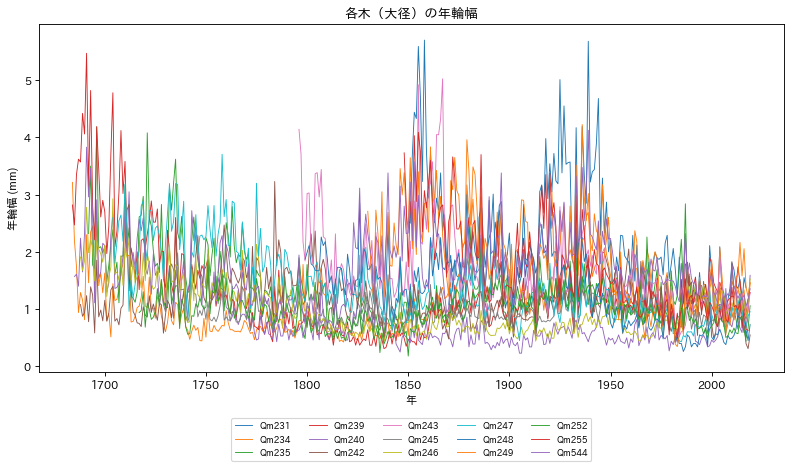

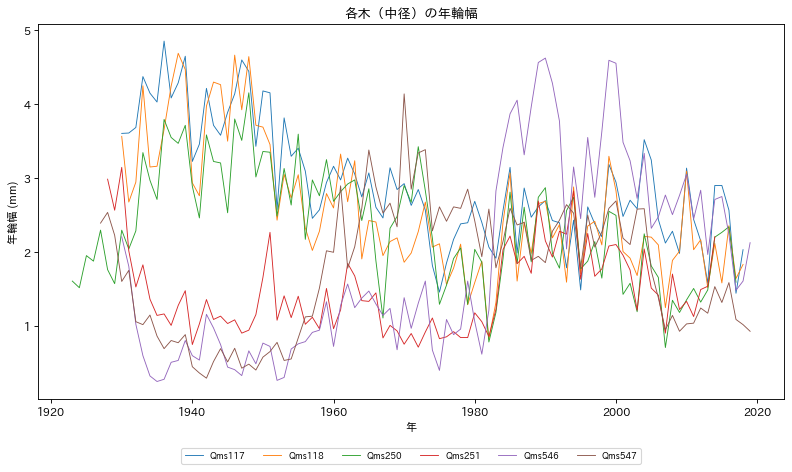

In [10]:
def core_to_tree(core_df):
    """コア別の年輪幅 → 木別（同じ木のコアを平均。1つでも欠ければ NaN）"""
    groups = {}
    for col in core_df.columns:
        groups.setdefault(col[:-1], []).append(col)
    return pd.DataFrame({tree: core_df[cols].mean(axis=1, skipna=False) for tree, cols in groups.items()})

tree_l = core_to_tree(trw_l)
tree_m = core_to_tree(trw_m)
print("大径木:", tree_l.shape[1], "本 / 中径木:", tree_m.shape[1], "本")

plot_series(tree_l, "各木（大径）の年輪幅")
plot_series(tree_m, "各木（中径）の年輪幅", ncol=6)

## 4. 年輪幅と気温の相関

木ごとに、年輪幅と年平均気温の相関係数（ピアソン）を、両方のデータがある年で計算する。

In [11]:
def corr_with_temp(tree_df, temp):
    return tree_df.apply(lambda s: s.corr(temp)).rename("相関係数")

corr_l = corr_with_temp(tree_l, temp).sort_values(ascending=False)
corr_m = corr_with_temp(tree_m, temp).sort_values(ascending=False)

print("【大径】相関係数（高い順）")
print(corr_l.round(3).to_string())
print(f"平均: {corr_l.mean():.3f}\n")
print("【中径】相関係数（高い順）")
print(corr_m.round(3).to_string())
print(f"平均: {corr_m.mean():.3f}")

【大径】相関係数（高い順）
Qm246    0.515
Qm240    0.344
Qm239    0.278
Qm242    0.116
Qm235   -0.040
Qm245   -0.084
Qm234   -0.092
Qm243   -0.138
Qm231   -0.165
Qm544   -0.207
Qm247   -0.236
Qm255   -0.288
Qm249   -0.289
Qm252   -0.434
Qm248   -0.470
平均: -0.079

【中径】相関係数（高い順）
Qms546    0.481
Qms251    0.179
Qms547    0.091
Qms250   -0.167
Qms118   -0.272
Qms117   -0.343
平均: -0.005


気温と正の相関を示す木は一部に限られ、符号が負の木も多い。木の成長は気温だけでなく、降水・競争・その木の個体差にも左右されるため、
「全部の木が気温に素直に反応する」わけではないことがわかる。

## 5. 回帰による気温の推定

### 5-1. 単回帰（1本の木から推定）
気温 = a + b × 年輪幅 を、相関が高かった上位3本（大径・中径それぞれ）について当てはめ、
年輪幅しかない過去の年の気温を推定する。
**ただし「相関が高い木を全期間のデータで選ぶ」ので、結果はやや甘めに出る**（5-3で選び方も含めて検証する）。

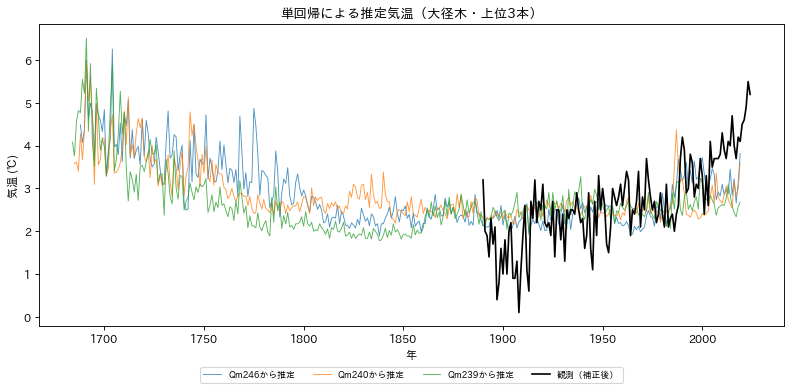

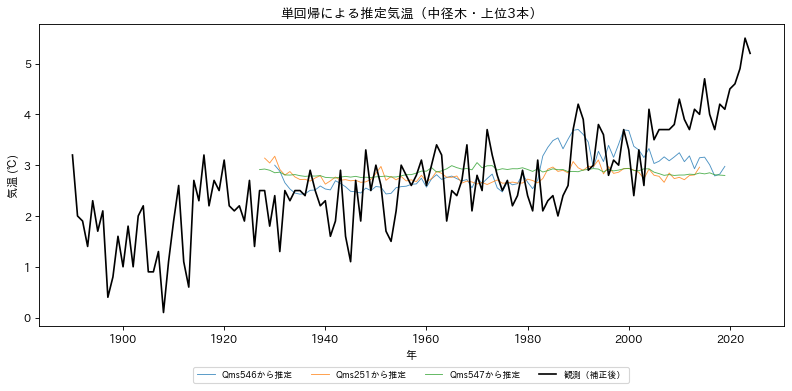

In [12]:
def fit_simple(tree_series, temp):
    """1本の木の年輪幅から気温への単回帰。重なる年だけで推定し、全年の推定気温を返す"""
    d = pd.concat([temp, tree_series.rename("ring")], axis=1).dropna()
    model = sm.OLS(d["temp"], sm.add_constant(d["ring"])).fit()
    estimate = model.params["const"] + model.params["ring"] * tree_series
    return model, estimate

def plot_estimates(estimates, temp, title):
    fig, ax = plt.subplots(figsize=(10, 5))
    for name, est in estimates.items():
        ax.plot(est.index, est.values, linewidth=0.8, alpha=0.8, label=f"{name}から推定")
    ax.plot(temp.index, temp.values, color="black", linewidth=1.5, label="観測（補正後）")
    ax.set(title=title, xlabel="年", ylabel="気温 (℃)")
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=4, fontsize=8)
    fig.tight_layout()
    plt.show()

top3_l = corr_l.head(3).index
top3_m = corr_m.head(3).index

est_l = {t: fit_simple(tree_l[t], temp)[1] for t in top3_l}
est_m = {t: fit_simple(tree_m[t], temp)[1] for t in top3_m}

plot_estimates(est_l, temp, "単回帰による推定気温（大径木・上位3本）")
plot_estimates(est_m, temp, "単回帰による推定気温（中径木・上位3本）")

### 5-2. 重回帰（全ての木から推定）
気温 = const + Σ（係数ᵢ × 木ᵢ の年輪幅）。全ての木の年輪幅がそろっている年だけで当てはめる。
推定できるのも「全木が揃っている年」に限られる。

【大径】使用年数=128  R²=0.417  自由度調整済みR²=0.339
  p<0.05 の係数: Qm246, Qm252

【中径】使用年数=85  R²=0.290  自由度調整済みR²=0.235
  p<0.05 の係数: Qms546



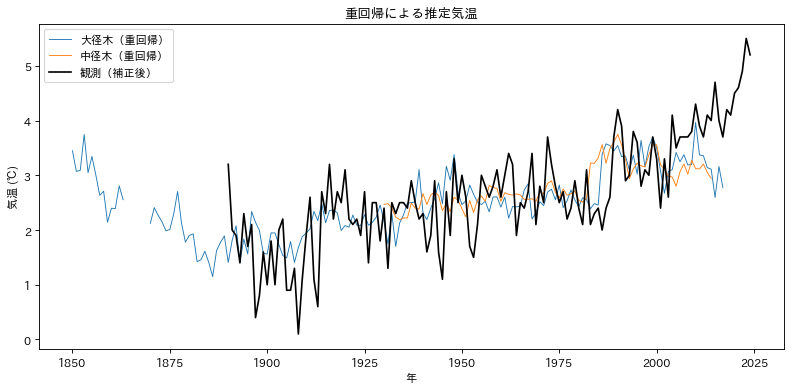

In [13]:
def fit_multi(tree_df, temp):
    d = tree_df.join(temp, how="inner").dropna()
    model = sm.OLS(d["temp"], sm.add_constant(d[tree_df.columns])).fit()
    estimate = model.params["const"] + tree_df.mul(model.params[tree_df.columns], axis=1).sum(axis=1, skipna=False)
    return model, estimate

model_l, est_multi_l = fit_multi(tree_l, temp)
model_m, est_multi_m = fit_multi(tree_m, temp)

for label, model in [("大径", model_l), ("中径", model_m)]:
    p = model.pvalues.drop("const")
    print(f"【{label}】使用年数={int(model.nobs)}  R²={model.rsquared:.3f}  自由度調整済みR²={model.rsquared_adj:.3f}")
    print(f"  p<0.05 の係数: {', '.join(p[p < 0.05].index) or 'なし'}\n")

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(est_multi_l.index, est_multi_l.values, linewidth=0.8, label="大径木（重回帰）")
ax.plot(est_multi_m.index, est_multi_m.values, linewidth=0.8, label="中径木（重回帰）")
ax.plot(temp.index, temp.values, color="black", linewidth=1.5, label="観測（補正後）")
ax.set(title="重回帰による推定気温", xlabel="年", ylabel="気温 (℃)")
ax.legend()
fig.tight_layout()
plt.show()

説明変数が多い（大径15本・中径6本）のに対して使える年数が限られるため、**学習期間に過剰適合している可能性が高い**。
多くの係数は有意ではなく、p<0.05 になる木は一部に限られる。木同士は同じ林にあるので完全に独立ではなく、
個々の係数の解釈には注意が必要。

### 5-3. 期間を分けた検証（両方向）
目的は「観測のある期間でモデルを作り、観測のない過去を推定する」ことなので、実際に当てられるかを**時間の向きを変えて2通り**で確かめる。
観測のある年（全木そろった年）を時間順に並べ、60%を学習、40%を検証にする。

- **A：過去 → 未来**　前半60%で学習し、後半40%を検証（時間外挿の確認）
- **B：未来 → 過去**　後半60%で学習し、前半40%を検証（実際の用途＝過去の推定に近い）

単回帰は**学習期間の相関だけで上位3本を選ぶ**（検証期間の情報を使わない）。指標は次の通り。

- `r`：検証期間での、推定と観測の相関
- `RMSE`：二乗平均平方根誤差
- `RE`（Reduction of Error）：`1 - SSE(モデル) / SSE(学習期間の平均)`。0 より大きければ「学習期間の平均で予測する」より良い
- `CE`（Coefficient of Efficiency）：`1 - SSE(モデル) / SSE(検証期間の平均)`。基準が検証期間自身の平均なので、RE より厳しい。**0 以下なら、検証期間の平均気温をそのまま使うより悪い**

気温は後半ほど高く、前半と後半で平均が違う。そのため r が低くても RE が正になることがあり、年ごとの変動を捉えているかは r と CE を合わせて判断する。

In [14]:
def skill(obs, pred, base_train):
    sse = ((obs - pred) ** 2).sum()
    return {
        "r": np.corrcoef(obs, pred)[0, 1],
        "RMSE": np.sqrt(((obs - pred) ** 2).mean()),
        "RE": 1 - sse / ((obs - base_train) ** 2).sum(),
        "CE": 1 - sse / ((obs - obs.mean()) ** 2).sum(),
    }

def validate(tree_df, temp, label, direction, train_frac=0.6, top_k=3):
    """direction='A'：前半で学習→後半で検証 / 'B'：後半で学習→前半で検証"""
    d = tree_df.join(temp, how="inner").dropna()      # 全木そろった年
    n_train = int(len(d) * train_frac)
    if direction == "A":
        train, test = d.iloc[:n_train], d.iloc[n_train:]
    else:
        train, test = d.iloc[len(d) - n_train:], d.iloc[:len(d) - n_train]
    base = train["temp"].mean()
    rows = []

    # 重回帰（全木）
    m = sm.OLS(train["temp"], sm.add_constant(train[tree_df.columns])).fit()
    pred = m.predict(sm.add_constant(test[tree_df.columns], has_constant="add"))
    rows.append({"木": label, "方向": direction, "モデル": "重回帰（全木）", **skill(test["temp"], pred, base)})

    # 単回帰（学習期間の相関で上位 top_k 本を選ぶ）
    corr_train = train[tree_df.columns].corrwith(train["temp"]).sort_values(ascending=False)
    for t in corr_train.index[:top_k]:
        m = sm.OLS(train["temp"], sm.add_constant(train[t])).fit()
        pred = m.predict(sm.add_constant(test[t], has_constant="add"))
        rows.append({"木": label, "方向": direction, "モデル": f"単回帰（{t}）", **skill(test["temp"], pred, base)})

    period = (f"{label} {direction}: 学習 {train.index.min()}–{train.index.max()}（{len(train)}年） / "
              f"検証 {test.index.min()}–{test.index.max()}（{len(test)}年）")
    return pd.DataFrame(rows), period

results, periods = [], []
for tree_df, label in [(tree_l, "大径"), (tree_m, "中径")]:
    for direction in ["A", "B"]:
        df_res, period = validate(tree_df, temp, label, direction)
        results.append(df_res)
        periods.append(period)

print("\n".join(periods))
validation = pd.concat(results, ignore_index=True)
validation.round(3)

大径 A: 学習 1890–1965（76年） / 検証 1966–2017（52年）
大径 B: 学習 1942–2017（76年） / 検証 1890–1941（52年）
中径 A: 学習 1930–1980（51年） / 検証 1981–2014（34年）
中径 B: 学習 1964–2014（51年） / 検証 1930–1963（34年）


,木,方向,モデル,r,RMSE,RE,CE
0,大径,A,重回帰（全木）,-0.170,1.675,-0.814,-4.854
1,大径,A,単回帰（Qm242）,0.181,1.382,-0.235,-2.987
2,大径,A,単回帰（Qm544）,-0.269,1.459,-0.376,-3.440
3,大径,A,単回帰（Qm231）,-0.125,1.439,-0.339,-3.321
4,大径,B,重回帰（全木）,-0.397,1.889,-1.365,-5.854
5,大径,B,単回帰（Qm246）,0.077,1.029,0.298,-1.035
6,大径,B,単回帰（Qm240）,0.299,1.170,0.092,-1.632
7,大径,B,単回帰（Qm239）,0.323,1.181,0.076,-1.678
8,中径,A,重回帰（全木）,-0.085,0.928,0.157,-0.893
9,中径,A,単回帰（Qms547）,-0.471,1.001,0.020,-1.200


**読み方**：「RE が正・r が低い・CE が負」のモデルは、年ごとの変動ではなく平均水準が近かっただけ、と考えるのが妥当。

## 6. まとめと限界

**わかったこと**
- **相関**：木によるばらつきが大きく、気温と正の相関を示すのは一部だけ（例：大径の `Qm246` で r≈0.52）。全木の平均はほぼ0（大径 -0.08、中径 -0.01）。
- **重回帰**：学習期間内の R² は 大径0.42 / 中径0.29 だが、自由度調整済みでは 0.34 / 0.24 に下がる。有意（p<0.05）な係数は大径2本（`Qm246`, `Qm252`）・中径1本（`Qms546`）のみ。
- **両方向の検証（5-3）**：重回帰は A・B のどちらでも、検証期間での r が負（大径 -0.17 / -0.40、中径 -0.09 / -0.17）。RE も、中径のA（+0.16）を除いてすべて負だった。
- 単回帰では RE が正になる木もある（Bに多い）が、r は最大でも約0.3で、負の木もある。**CE は全モデル・両方向で負**で、検証期間の平均気温をそのまま使うより良いモデルは1つもなかった。RE が正なのは、年ごとの変動ではなく平均水準が合っただけと考えられる。
- 全期間で相関1位だった `Qm246` は、前半（学習期間）だけで選ぶと上位3本に入らない。**木の成長と気温の関係は時期によって安定していない**。

**結論**：この手法（生の年輪幅から年平均気温への線形回帰）では、過去と未来のどちらの向きでも、気温を信頼できる精度で推定できなかった。年輪幅から過去の気温を復元できたとは言えない。

**限界と今後の課題**
1. **年輪幅の樹齢トレンドを除去していない**。5-1の図で推定気温が過去ほど高く出ているのは、樹齢とともに年輪が細くなる傾向を拾っている可能性がある。標準的な年代学では、スプライン等で標準化（detrending）してから気温と比べる。これが最優先の改善点。
2. **年平均気温を使っている**。成長期（例：6〜8月）の気温や降水との関係の方が強い可能性があり、`Kushiro_kion.csv` の月別データで確認できる。
3. 気温補正は標高差から一律 -3℃ とした簡易的なもの。観測地点（釧路）と調査地は離れている。
4. 検証は期間を1回ずつ分割したもので、各期間は50〜70年程度と短い。分割を複数回行う交差検証をすると、より信頼できる。